# 03 — Individual protein performance

The seven shortlisted proteins are evaluated **one at a time** for the final binary task.

**HEALTHY**
- `Healthy_control`
- `Non_stable_fibrotic_ILA`

**UNHEALTHY**
- `Stable_fibrotic_ILA`
- `Progressive_ILA`
- `Established_ILD`

The positive class is **UNHEALTHY**.

This stage asks whether any single protein is already sufficient. Because the individual sensitivity/specificity values were not strong enough for the intended use, the next notebook evaluates combinations of the seven proteins.

In [1]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from IPython.display import display
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, confusion_matrix, f1_score, roc_auc_score
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler

TRAIN_FILENAME = "TrainData.csv"
TEST_FILENAME = "TestData.csv"
TARGET = "clinic_group"
RANDOM_STATE = 42

PROTEINS = [
    "NPX_GDF15",
    "NPX_SFTPB",
    "NPX_MMP7",
    "NPX_FGA2242",
    "NPX_VCAM1",
    "NPX_WFDC2",
    "NPX_AREG",
]

HEALTHY_GROUPS = {"Healthy_control", "Non_stable_fibrotic_ILA"}
UNHEALTHY_GROUPS = {"Stable_fibrotic_ILA", "Progressive_ILA", "Established_ILD"}

def resolve_data_file(filename):
    for path in [Path("data") / filename, Path(filename)]:
        if path.exists():
            return path
    raise FileNotFoundError(
        f"Could not find {filename}. Put the authorized file in ./data/ "
        "or next to this notebook. Do not commit it to GitHub."
    )

def encode_target(series):
    mapping = {
        **{g: 0 for g in HEALTHY_GROUPS},
        **{g: 1 for g in UNHEALTHY_GROUPS},
    }
    unexpected = set(series.dropna().astype(str).unique()) - set(mapping)
    if unexpected:
        raise ValueError(f"Unexpected clinic_group values: {sorted(unexpected)}")
    return series.astype(str).map(mapping).to_numpy()

train = pd.read_csv(resolve_data_file(TRAIN_FILENAME))
test = pd.read_csv(resolve_data_file(TEST_FILENAME))
train.columns = train.columns.astype(str).str.strip()
test.columns = test.columns.astype(str).str.strip()

for name, data in [("train", train), ("test", test)]:
    missing = [c for c in [TARGET] + PROTEINS if c not in data.columns]
    if missing:
        raise ValueError(f"Missing columns in {name}: {missing}")

y_train = encode_target(train[TARGET])
y_test = encode_target(test[TARGET])


In [2]:
def build_model():
    return Pipeline([
        ("imputer", SimpleImputer(strategy="constant", fill_value=-6)),
        ("scaler", StandardScaler()),
        ("classifier", LogisticRegression(
            max_iter=4000,
            class_weight="balanced",
            random_state=RANDOM_STATE,
        )),
    ])

def evaluate_protein(protein):
    X_train = train[[protein]].apply(pd.to_numeric, errors="coerce")
    X_test = test[[protein]].apply(pd.to_numeric, errors="coerce")

    model = build_model()
    model.fit(X_train, y_train)

    pred = model.predict(X_test)
    prob = model.predict_proba(X_test)[:, 1]
    tn, fp, fn, tp = confusion_matrix(y_test, pred, labels=[0, 1]).ravel()

    return {
        "Protein": protein,
        "Accuracy": accuracy_score(y_test, pred),
        "F1_UNHEALTHY": f1_score(y_test, pred, pos_label=1, zero_division=0),
        "Sensitivity_UNHEALTHY": tp / (tp + fn),
        "Specificity_HEALTHY": tn / (tn + fp),
        "ROC_AUC": roc_auc_score(y_test, prob),
        "TN": int(tn),
        "FP": int(fp),
        "FN": int(fn),
        "TP": int(tp),
    }

IndividualResults = pd.DataFrame(
    [evaluate_protein(protein) for protein in PROTEINS]
).sort_values("ROC_AUC", ascending=False).reset_index(drop=True)

display(IndividualResults)


,Protein,Accuracy,F1_UNHEALTHY,Sensitivity_UNHEALTHY,Specificity_HEALTHY,ROC_AUC,TN,FP,FN,TP
0,NPX_SFTPB,0.710,0.760331,0.707692,0.714286,0.776264,50,20,38,92
1,NPX_WFDC2,0.670,0.731707,0.692308,0.628571,0.738626,44,26,40,90
2,NPX_MMP7,0.635,0.683983,0.607692,0.685714,0.720824,48,22,51,79
3,NPX_GDF15,0.665,0.714894,0.646154,0.700000,0.719396,49,21,46,84
4,NPX_AREG,0.675,0.732510,0.684615,0.657143,0.689286,46,24,41,89
5,NPX_VCAM1,0.575,0.622222,0.538462,0.642857,0.615549,45,25,60,70
6,NPX_FGA2242,0.530,0.601695,0.546154,0.500000,0.555824,35,35,59,71


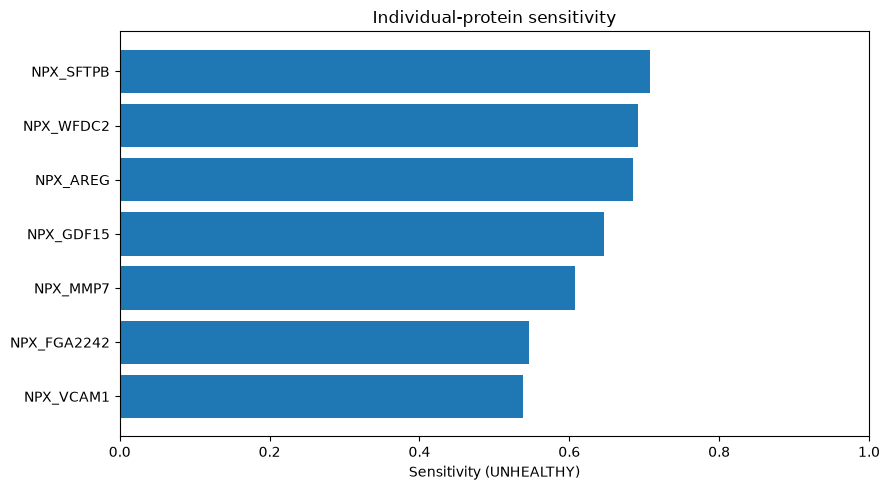

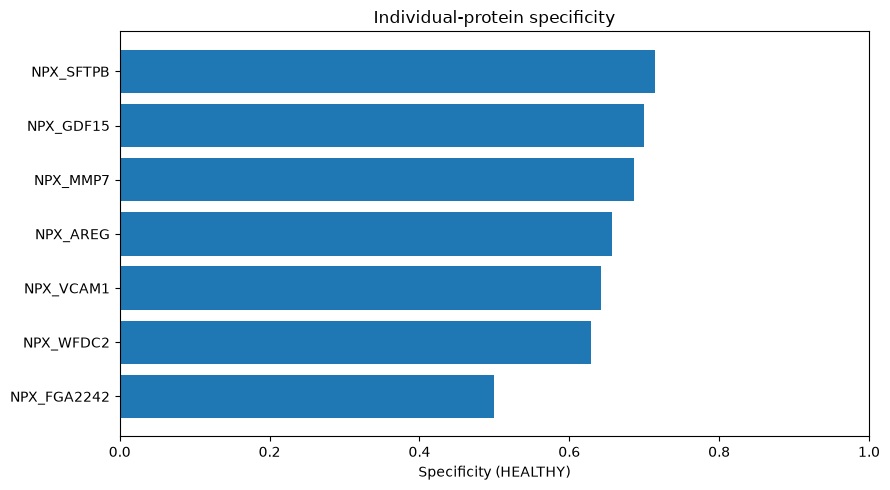

In [3]:
plot_data = IndividualResults.sort_values("Sensitivity_UNHEALTHY")

plt.figure(figsize=(9, 5))
plt.barh(plot_data["Protein"], plot_data["Sensitivity_UNHEALTHY"])
plt.xlabel("Sensitivity (UNHEALTHY)")
plt.xlim(0, 1)
plt.title("Individual-protein sensitivity")
plt.tight_layout()
plt.show()

plot_data = IndividualResults.sort_values("Specificity_HEALTHY")

plt.figure(figsize=(9, 5))
plt.barh(plot_data["Protein"], plot_data["Specificity_HEALTHY"])
plt.xlabel("Specificity (HEALTHY)")
plt.xlim(0, 1)
plt.title("Individual-protein specificity")
plt.tight_layout()
plt.show()


No individual protein provided the balance of sensitivity and specificity sought for the final model. The next step therefore evaluates **all possible combinations** of the seven shortlisted proteins.